# Modelado de uplift — Hillstrom (2008) — campañas de e-mail en un e-commerce de indumentaria
Fases 3 a 6 de CRISP-DM: preparación, modelado (meta-learners S/T/X), evaluación (Qini, AUUC, IPW) y despliegue (API, dashboard, drift).

Con `RUN = True` se re-ejecuta el pipeline completo para `hillstrom`.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import numpy as np, pandas as pd
from IPython.display import Image, display
from uplift.dataset import load_config
pd.set_option("display.float_format", "{:.4f}".format)
cfg = load_config("hillstrom")
FIG = cfg.figures_dir
def show(name):
    p = FIG / f"{name}.png"
    if p.exists():
        display(Image(str(p)))
RUN = not cfg.bundle_path.exists()
print(cfg.modeling)

{'sample_size': None, 'test_size': 0.3, 'cv_folds': 5, 'cv_repeats': 3, 'n_boot': 200, 'n_jobs': 2}


## 1. Entrenamiento y selección por validación cruzada

Filas: {'total': 64000, 'train': 44800, 'test': 19200}


outcome,conversion,spend,visit
learner,,,
baseline,0.0546,0.0788,0.0677
s_learner_lgbm,0.0567,0.1147,0.0898
s_learner_linear,0.0377,0.1067,0.0878
t_learner_hurdle,NaN,0.1268,NaN
t_learner_lgbm,0.0777,0.0705,0.0691
t_learner_linear,0.0715,0.1080,0.0857
x_learner_lgbm,0.0573,0.0756,0.0701
x_learner_linear,0.0568,0.1079,0.0781


Seleccionados: {'conversion': 't_learner_lgbm', 'spend': 't_learner_hurdle', 'visit': 's_learner_lgbm'}


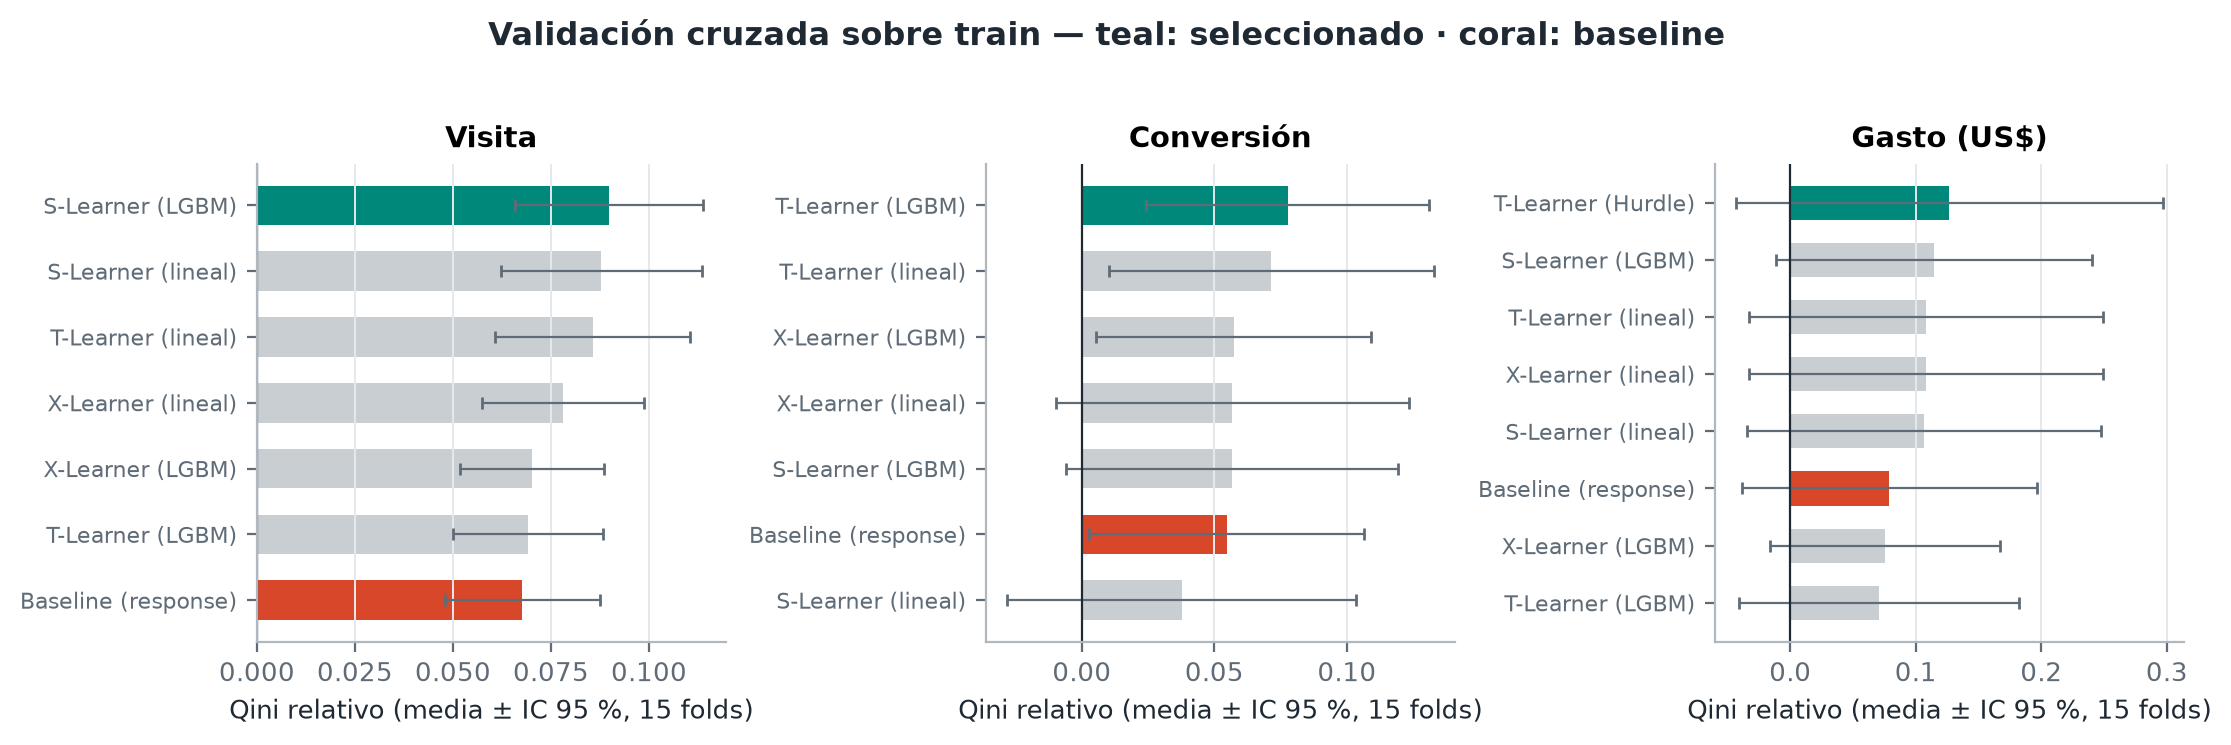

In [2]:
if RUN:
    from uplift import train
    train.run(cfg)
metrics = json.load(open(cfg.reports_dir / 'metrics.json'))
print('Filas:', metrics.get('n_rows'))
cv = pd.DataFrame(metrics['cv_summary'])
display(cv.pivot(index='learner', columns='outcome', values='mean'))
print('Seleccionados:', metrics['selected'])
show('cv_model_selection')

## 2. Evaluación en test

auuc        qini_relative        uplift_at_10  \
treatment                      mens womens          mens womens         mens   
outcome    learner                                                             
conversion baseline          0.0031 0.0025        0.1130 0.1981       0.0124   
           s_learner_lgbm    0.0024 0.0053        0.0873 0.4260       0.0070   
           s_learner_linear -0.0021 0.0019       -0.0813 0.1516       0.0139   
           t_learner_lgbm    0.0005 0.0033        0.0188 0.2583       0.0151   
           t_learner_linear -0.0016 0.0026       -0.0632 0.2049       0.0160   
           x_learner_lgbm    0.0002 0.0035        0.0075 0.2807       0.0109   
           x_learner_linear -0.0001 0.0033       -0.0060 0.2637       0.0176   
spend      baseline             NaN    NaN       -0.0058 0.3974       0.3965   
           s_learner_lgbm       NaN    NaN       -0.1157 0.2231       0.5804   
           s_learner_linear     NaN    NaN       -0.1844 0.2829       1.1854   
           t_learner_hurdle     NaN    NaN        0.0531 0.3177       0.5999   
           t_learner_lgbm       NaN    NaN       -0.0276 0.4293       0.1016   
           t_learner_linear     NaN    NaN       -0.1838 0.2820       1.1854   
           x_learner_lgbm       NaN    NaN       -0.0812 0.4375      -0.2424   
           x_learner_linear     NaN    NaN       -0.1839 0.2820       1.1854   
visit      baseline          0.0192 0.0100        0.0669 0.0579       0.1509   
           s_learner_lgbm    0.0138 0.0266        0.0457 0.1546       0.1490   
           s_learner_linear  0.0105 0.0241        0.0340 0.1394       0.1481   
           t_learner_lgbm    0.0128 0.0268        0.0455 0.1560       0.1462   
           t_learner_linear  0.0082 0.0245        0.0266 0.1428       0.1505   
           x_learner_lgbm    0.0109 0.0247        0.0403 0.1448       0.1550   
           x_learner_linear  0.0055 0.0243        0.0177 0.1426       0.1420   

                                     
treatment                    womens  
outcome    learner                   
conversion baseline          0.0101  
           s_learner_lgbm    0.0099  
           s_learner_linear  0.0021  
           t_learner_lgbm    0.0099  
           t_learner_linear -0.0029  
           x_learner_lgbm    0.0077  
           x_learner_linear  0.0002  
spend      baseline          1.2289  
           s_learner_lgbm    0.4365  
           s_learner_linear  1.3882  
           t_learner_hurdle  0.0432  
           t_learner_lgbm    0.5834  
           t_learner_linear  1.3842  
           x_learner_lgbm    0.3955  
           x_learner_linear  1.3842  
visit      baseline          0.0551  
           s_learner_lgbm    0.0904  
           s_learner_linear  0.0617  
           t_learner_lgbm    0.0320  
           t_learner_linear  0.0641  
           x_learner_lgbm    0.0461  
           x_learner_linear  0.0459

visit      mens    baseline           Qini rel=0.067 IC95%=[0.026 0.114]
visit      mens    s_learner_lgbm     Qini rel=0.046 IC95%=[-0.001  0.084]
visit      womens  baseline           Qini rel=0.058 IC95%=[-0.007  0.117]
visit      womens  s_learner_lgbm     Qini rel=0.155 IC95%=[0.076 0.278]
conversion mens    baseline           Qini rel=0.113 IC95%=[-0.036  0.259]
conversion mens    t_learner_lgbm     Qini rel=0.019 IC95%=[-0.158  0.166]
conversion womens  baseline           Qini rel=0.198 IC95%=[-0.121  1.151]
conversion womens  t_learner_lgbm     Qini rel=0.258 IC95%=[-0.023  2.345]
spend      mens    baseline           Qini rel=-0.006 IC95%=[-0.901  0.237]
spend      mens    t_learner_hurdle   Qini rel=0.053 IC95%=[-0.391  0.369]
spend      womens  baseline           Qini rel=0.397 IC95%=[0.09  6.233]
spend      womens  t_learner_hurdle   Qini rel=0.318 IC95%=[-0.034  3.859]


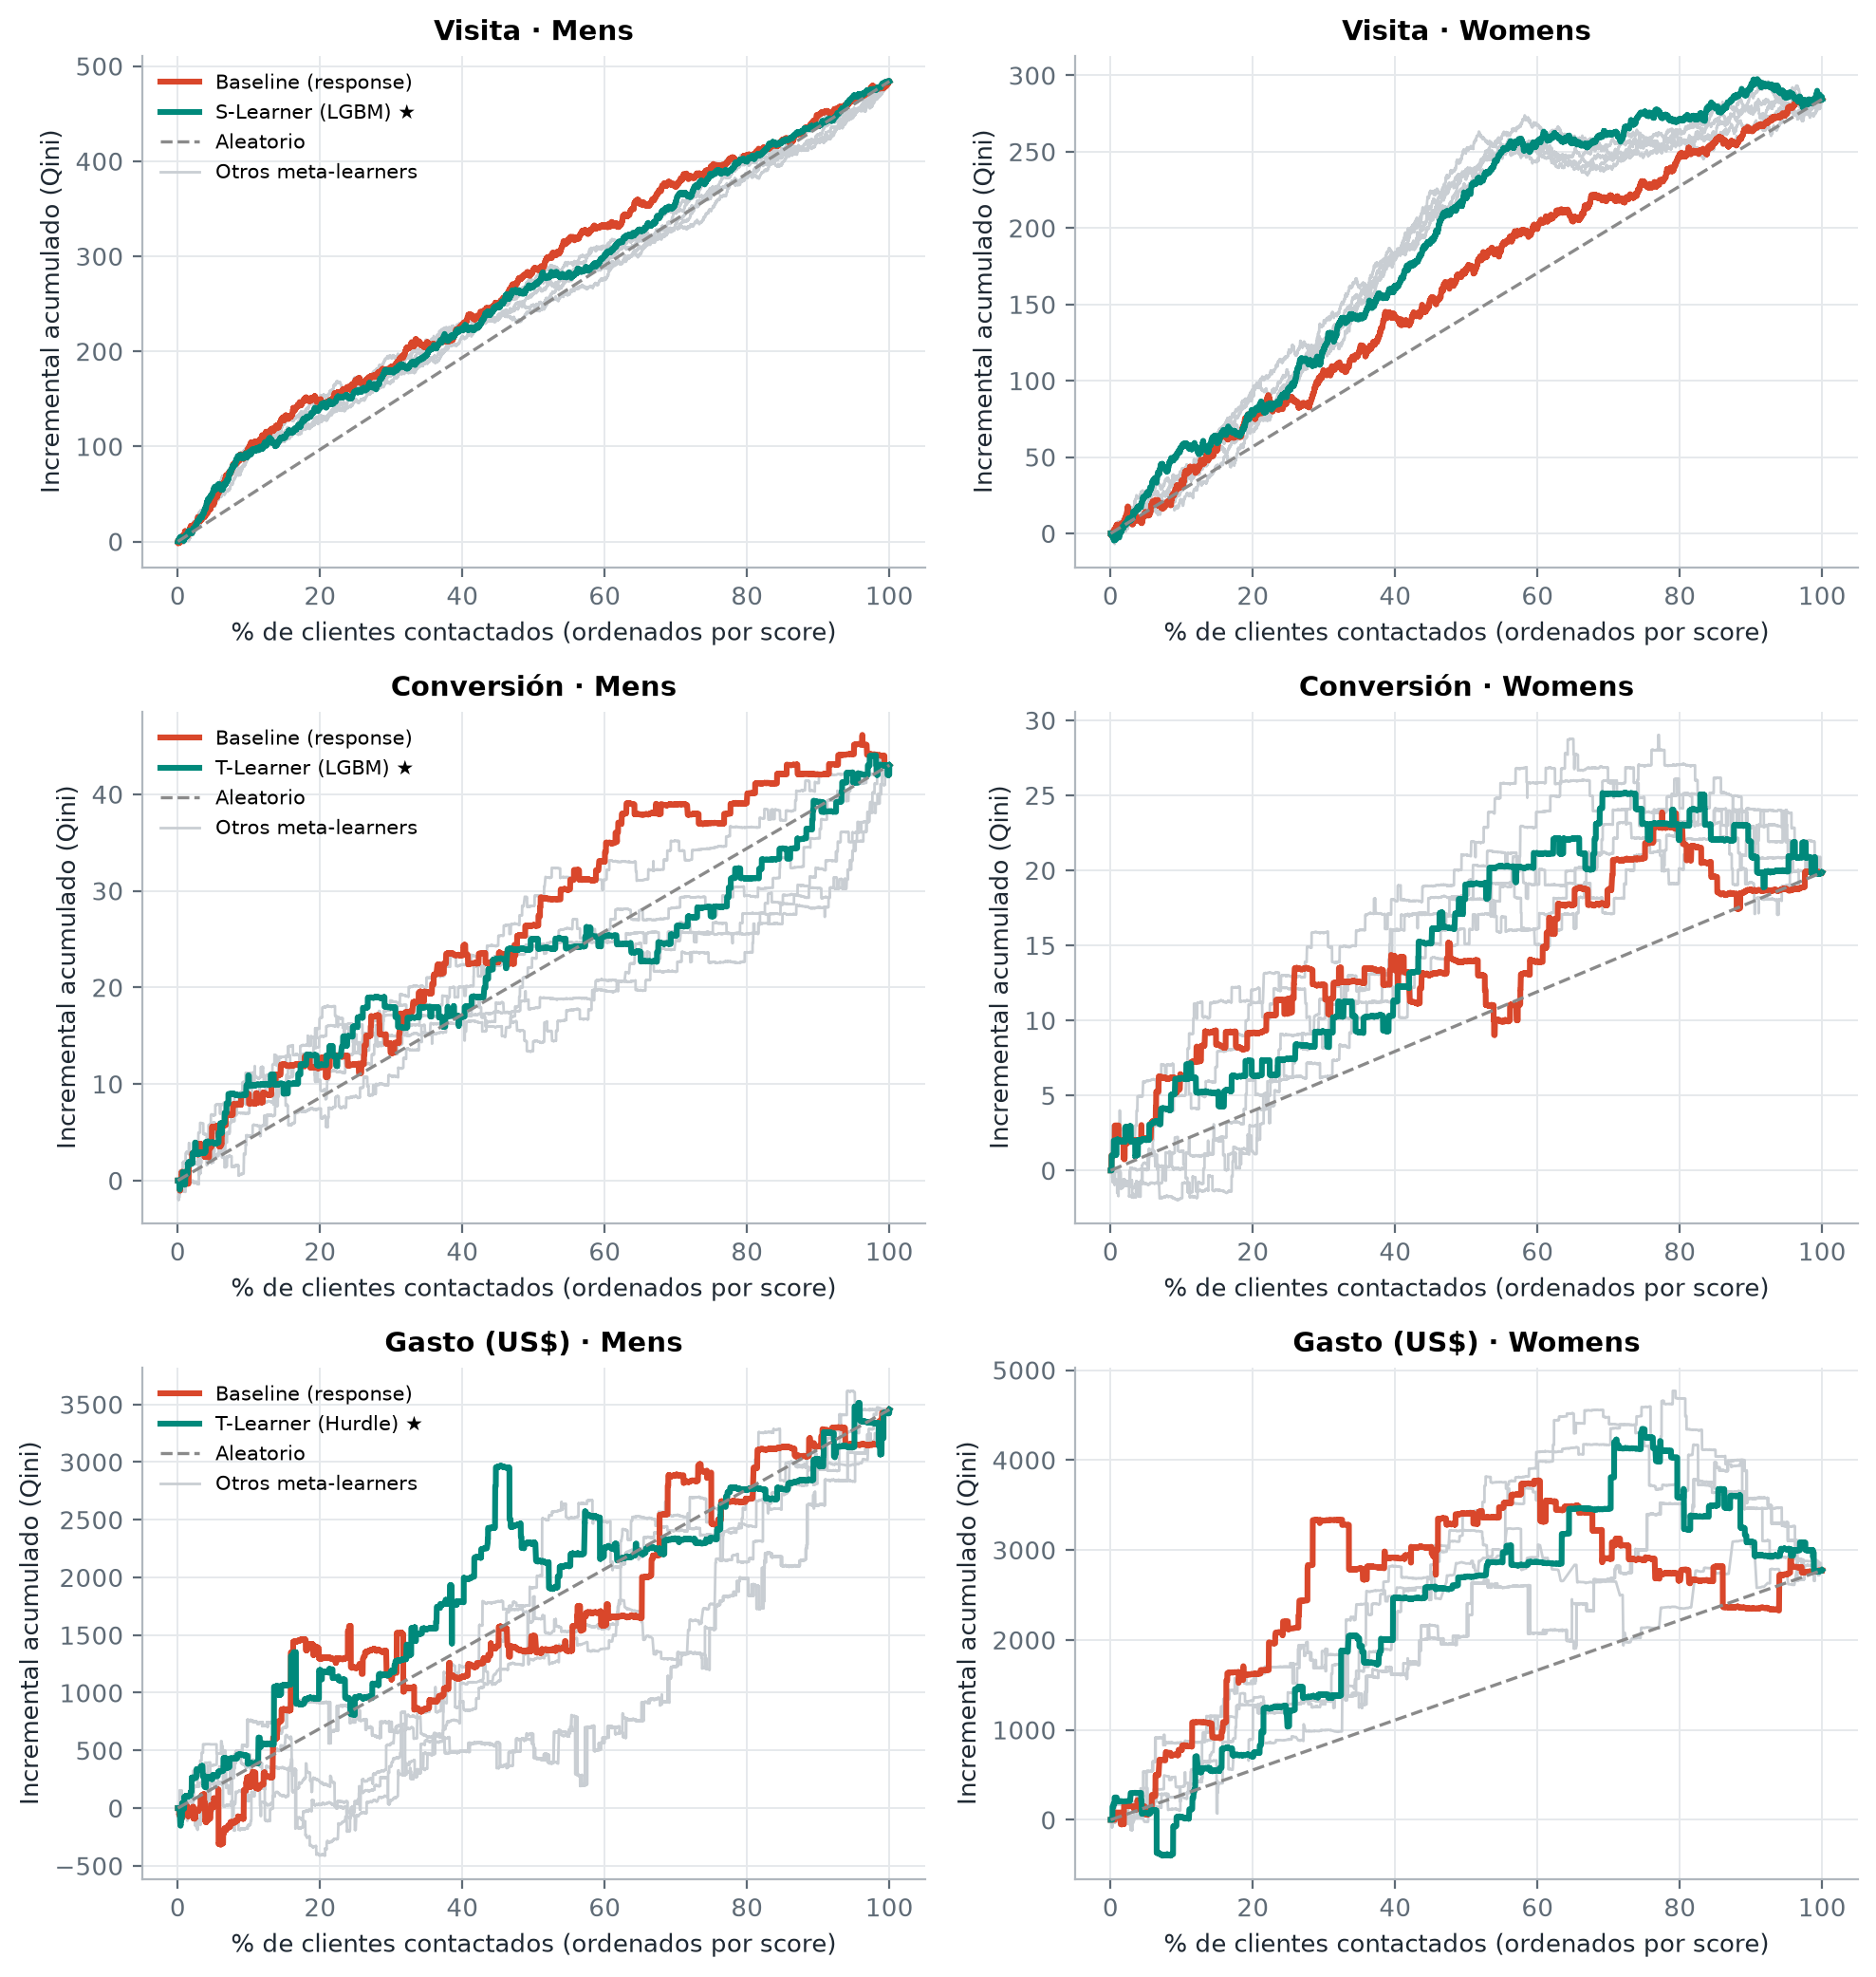

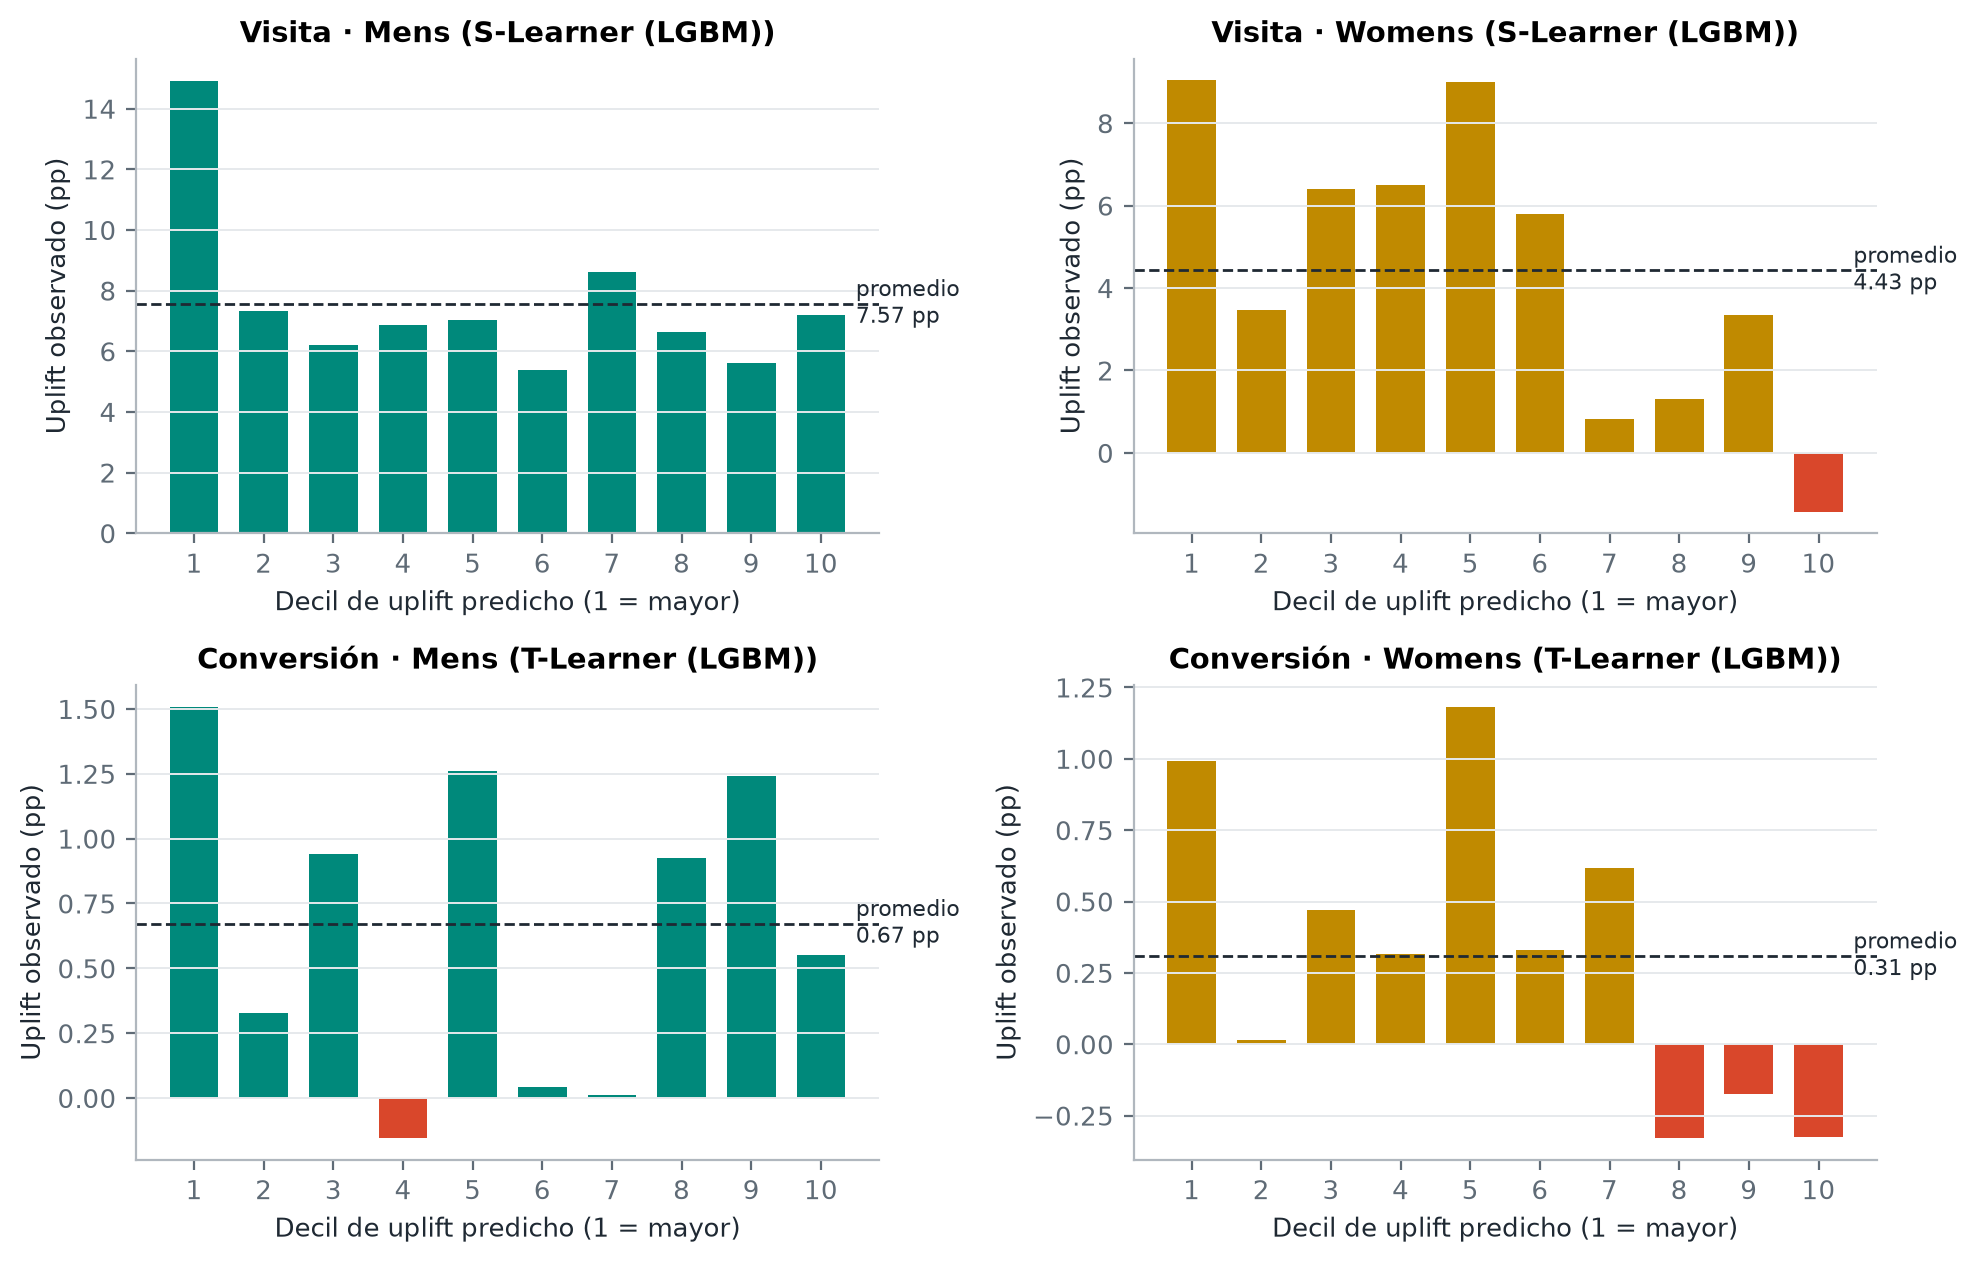

In [3]:
tm = pd.read_csv(cfg.tables_dir / 'test_metrics.csv')
display(tm.pivot_table(index=['outcome','learner'], columns='treatment', values=['qini_relative','auuc','uplift_at_10']))
for o, v in metrics['results'].items():
    sel = metrics['selected'][o]
    for a in [t.label for t in cfg.treatments]:
        for key in ('baseline', sel):
            print(f"{o:10s} {a:7s} {key:18s} Qini rel={v[key][a]['qini_relative']:.3f} IC95%={np.round(v[key][a]['qini_relative_ci95'], 3)}")
show('qini_curves')
show('uplift_by_decile')

## 3. Interpretación del CATE

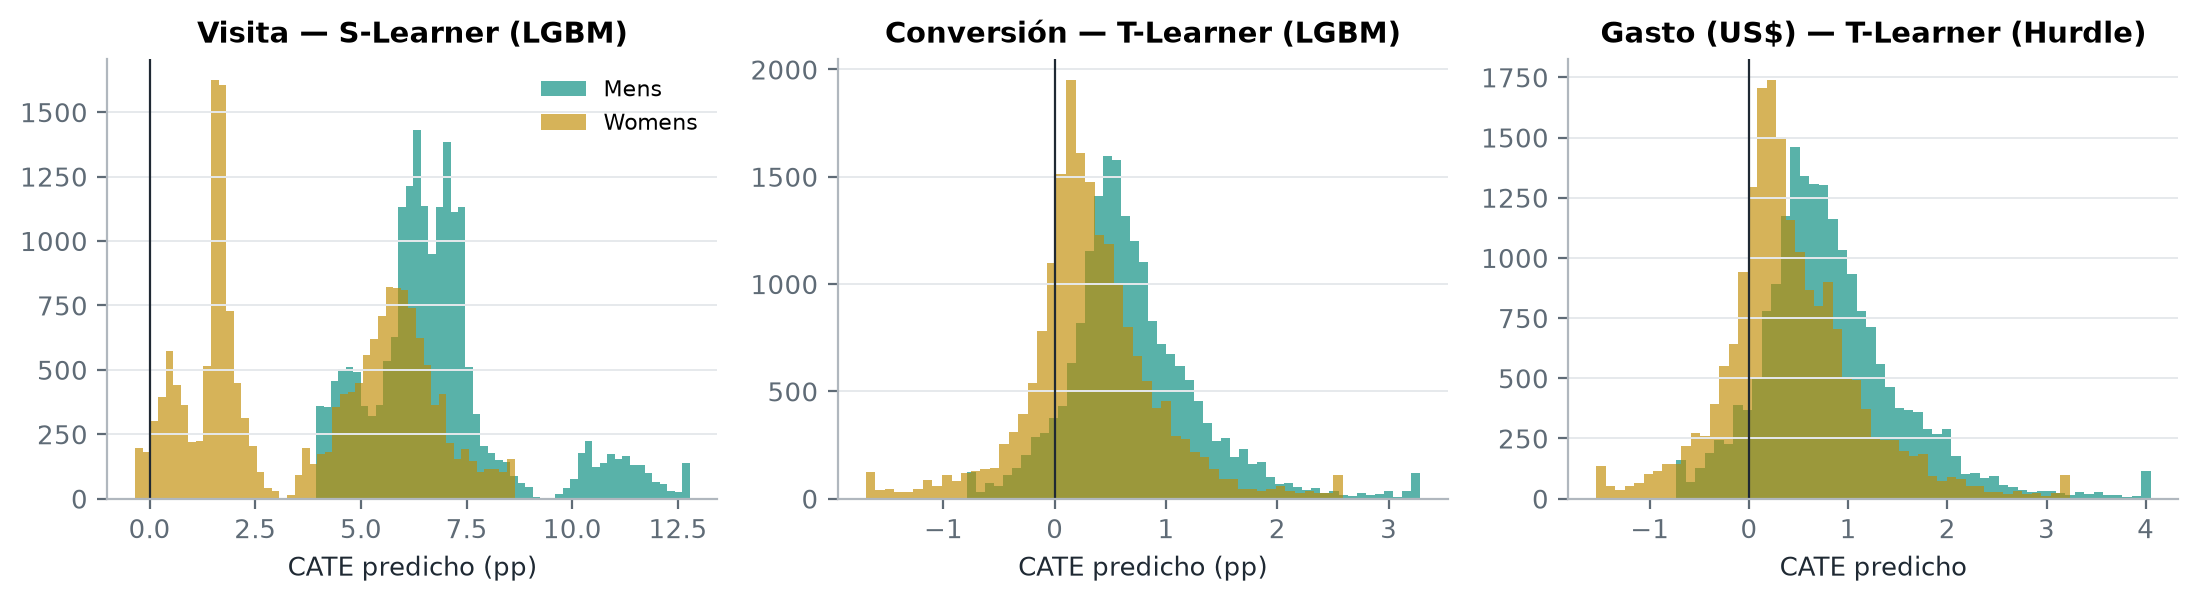

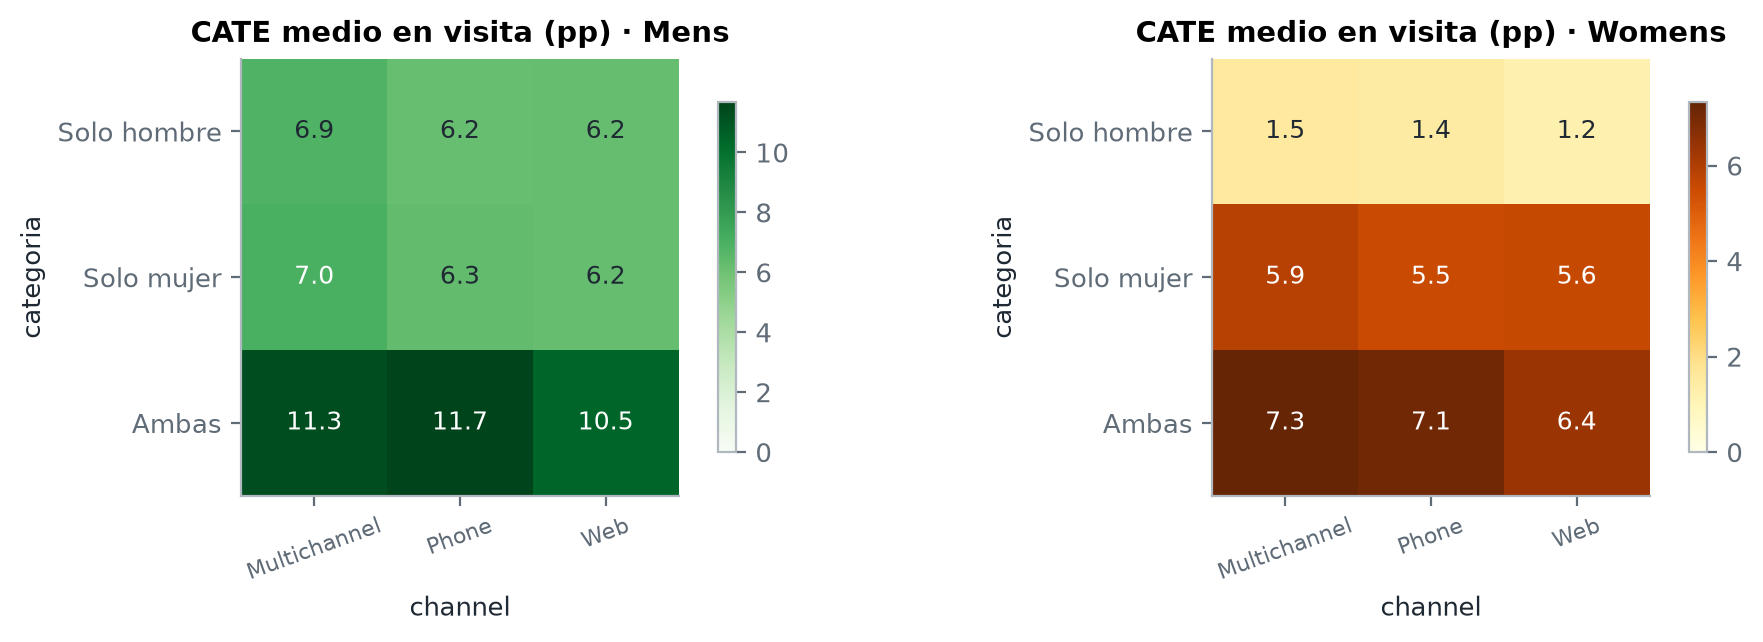

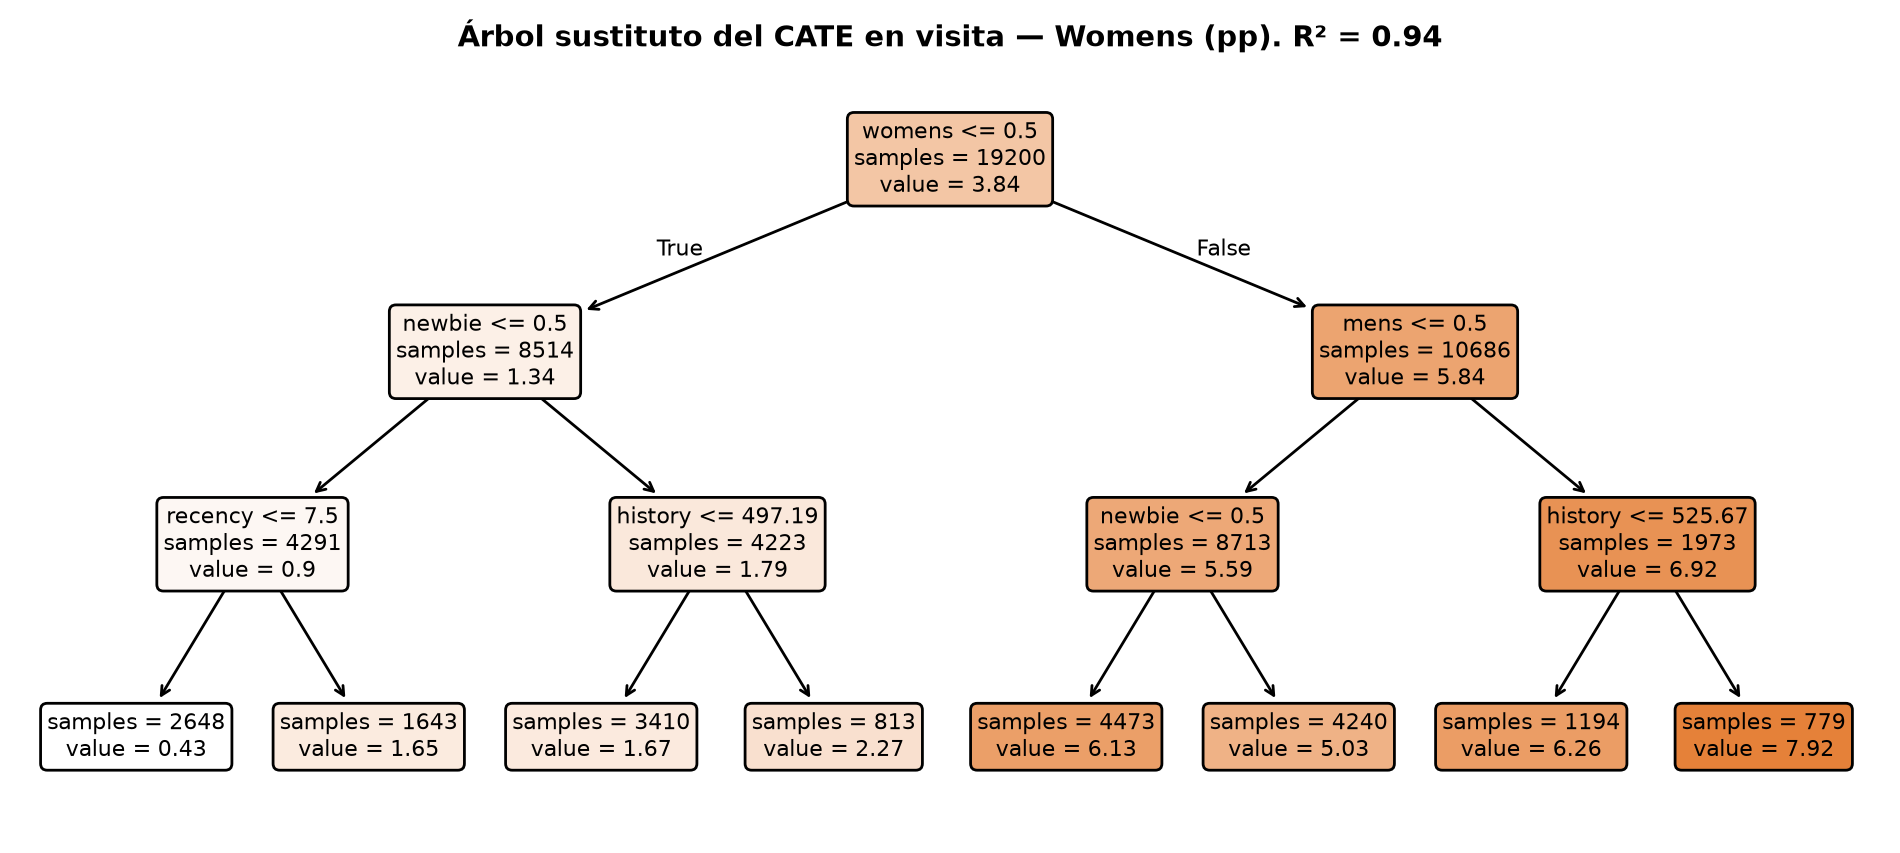

In [4]:
if RUN or not (FIG / 'surrogate_tree.png').exists():
    from uplift import figures
    figures.run(cfg)
show('cate_distribution')
show('cate_segments')
show('surrogate_tree')

## 4. Política bajo presupuesto (IPW, con IC 95 %)

,policy,share_contacted,share_mens,share_womens,inc_visit_per_1000,inc_visit_lo,inc_visit_hi,inc_conversion_per_1000,inc_conversion_lo,inc_conversion_hi,inc_spend_per_1000,inc_spend_lo,inc_spend_hi,cost_per_1000,profit_per_1000,profit_lo,profit_hi,roi
0,No enviar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN
1,Enviar a todos — Mens,1.0000,1.0000,0.0000,75.7196,62.4675,88.9718,6.7272,3.4118,10.0426,540.5319,41.1241,1039.9397,100.0000,116.2128,-83.5504,315.9759,1.1621
2,Enviar a todos — Womens,1.0000,0.0000,1.0000,44.3234,31.7871,56.8598,3.0956,0.1297,6.0614,432.4308,-86.3103,951.1719,100.0000,72.9723,-134.5241,280.4688,0.7297
3,Aleatoria (50%),0.5000,0.2503,0.2497,34.2723,24.9835,43.5611,1.4004,-0.8716,3.6724,224.4576,-132.0990,581.0141,50.0000,39.7830,-102.8396,182.4056,0.7957
4,Modelo (50%),0.5000,0.3548,0.1452,43.3854,33.5413,53.2294,3.9047,1.4347,6.3747,352.3326,-19.9820,724.6473,50.0000,90.9331,-57.9928,239.8589,1.8187
5,"Modelo (sin restricción, uplift>0)",0.9533,0.6579,0.2954,69.4293,56.6152,82.2433,6.4037,3.2352,9.5723,514.0591,35.0115,993.1066,95.3281,110.2955,-81.3235,301.9145,1.1570


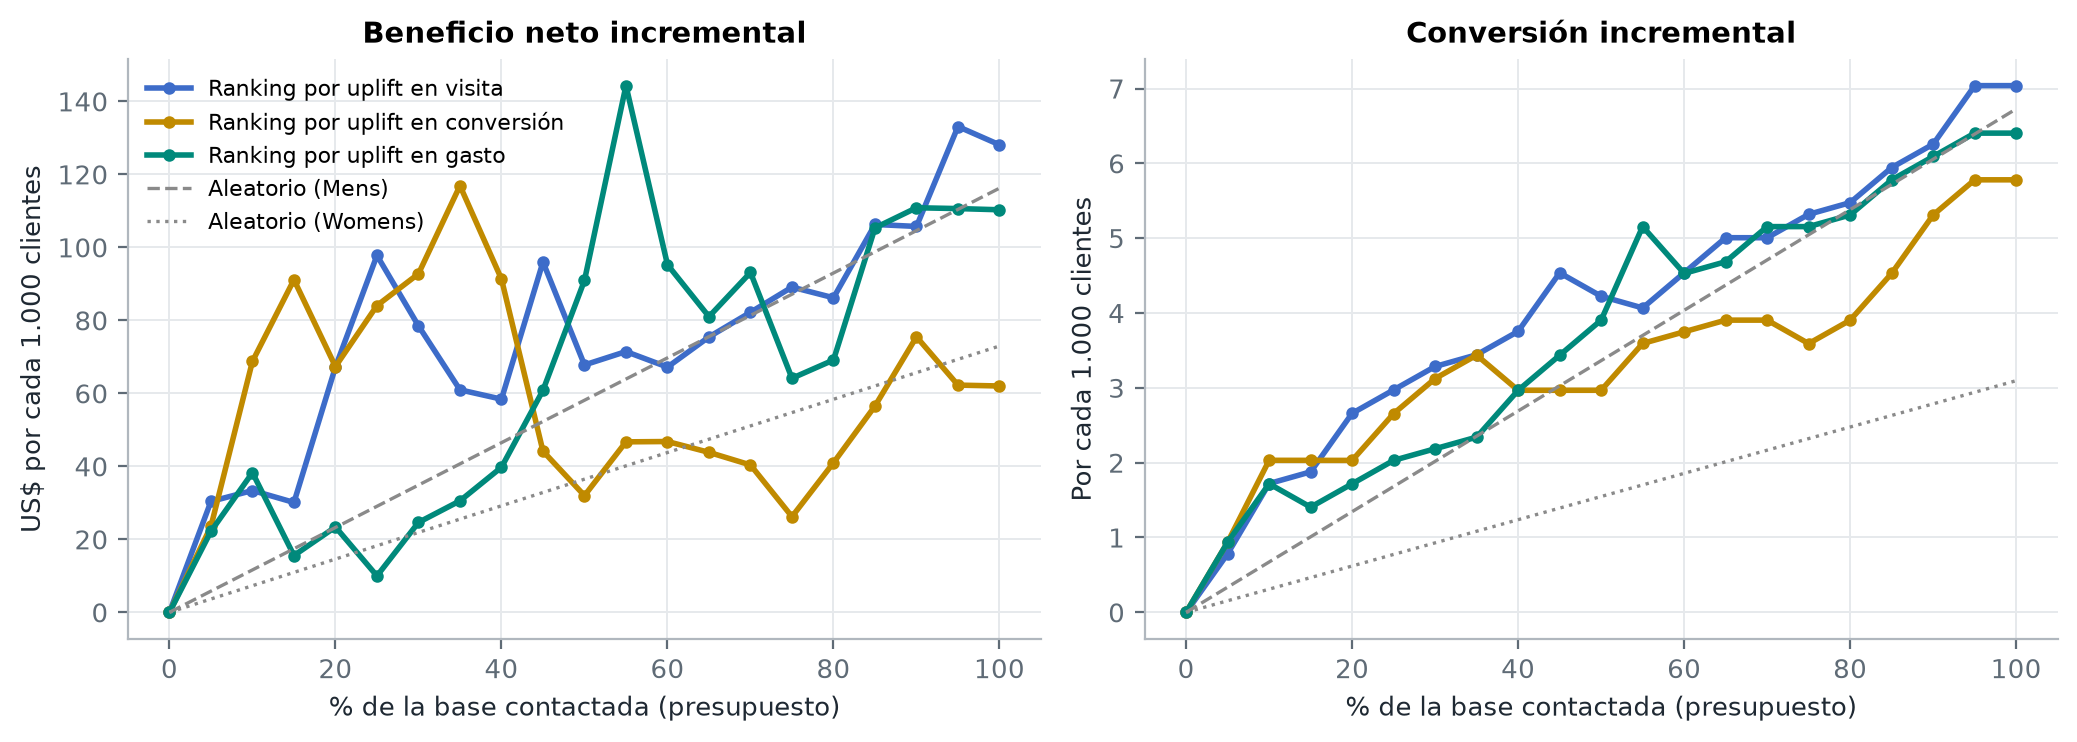

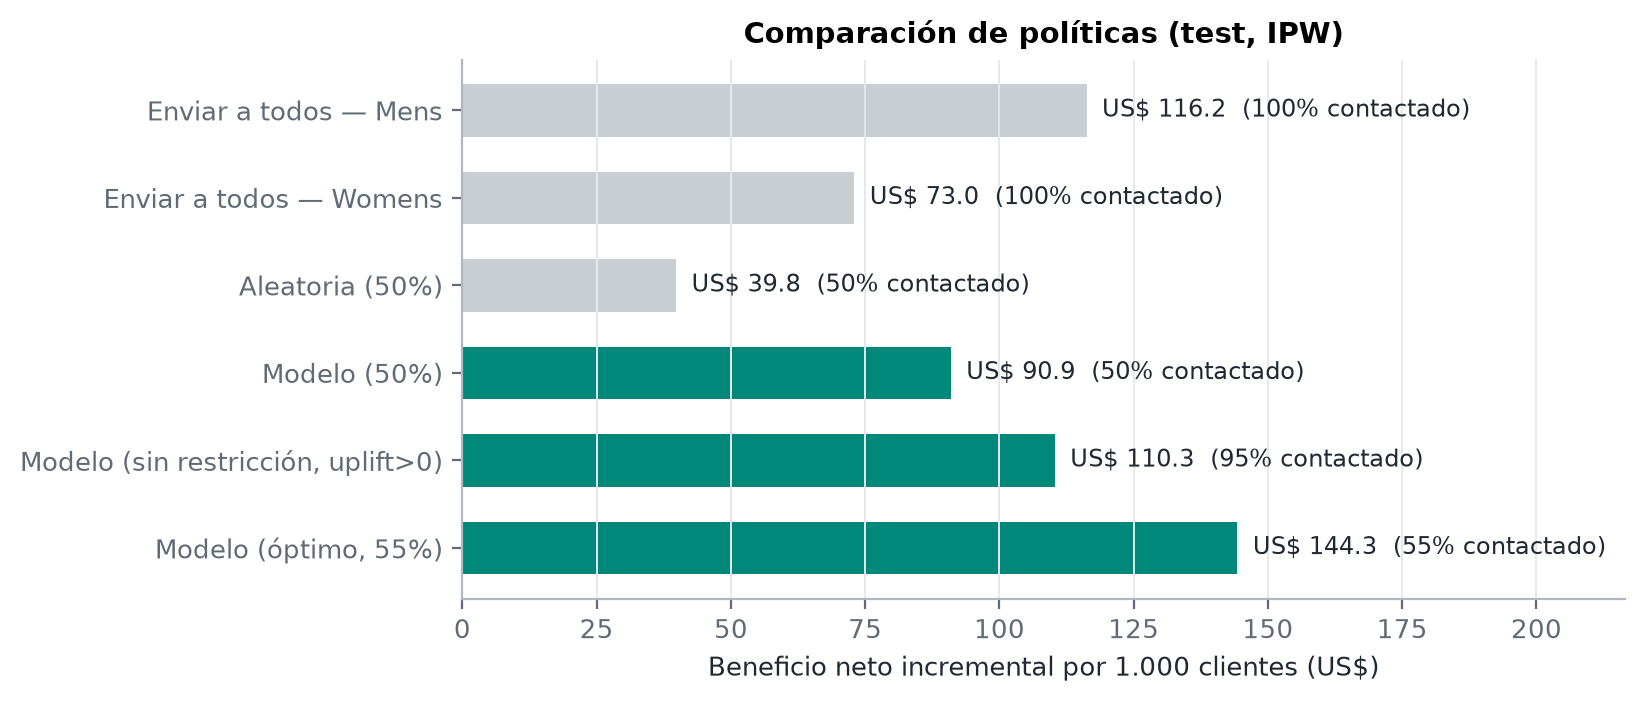

In [5]:
rank = list(cfg.business['values'])[0] if cfg.business['values'] else cfg.primary_outcome
display(pd.read_csv(cfg.tables_dir / f'policy_benchmark_{rank}.csv'))
show('budget_curves')
show('policy_benchmark')

## 5. Despliegue: scoring vía API

In [6]:
from fastapi.testclient import TestClient
from api.main import app
from uplift.data import load_split
client = TestClient(app)
cust = load_split('test', cfg)[cfg.raw_features].head(2).to_dict(orient='records')
client.post(f'/{cfg.name}/predict', json={'customers': cust}).json()

{'dataset': 'hillstrom',
 'model_version': '2.0.0',
 'objective': 'profit',
 'predictions': [{'uplift': {'visit': {'mens': 0.051864328947965915,
     'womens': 0.015704206580476374},
    'conversion': {'mens': 0.007958801171777932,
     'womens': 0.004283609486804803},
    'spend': {'mens': 1.1176582527250318, 'womens': 0.6933987944589932}},
   'recommended_treatment': 'mens',
   'expected_value': 0.3470633010900127,
   'expected_profit_usd': 0.3470633010900127},
  {'uplift': {'visit': {'mens': 0.055426661863210214,
     'womens': 0.024143511323189537},
    'conversion': {'mens': 0.0030871271776487094,
     'womens': 0.0018211541458460602},
    'spend': {'mens': 0.39331300607777475, 'womens': 0.27273620340194116}},
   'recommended_treatment': 'mens',
   'expected_value': 0.05732520243110992,
   'expected_profit_usd': 0.05732520243110992}]}

## 6. Monitoreo de drift (ventanas simuladas)

In [7]:
from uplift import monitoring
monitoring.run(cfg)

  W1: PSI máx=0.003 alerta=False


  W2: PSI máx=0.004 alerta=False


  W3: PSI máx=0.005 alerta=False


  W4: PSI máx=0.003 alerta=False


  W5 (drift): PSI máx=0.304 alerta=True


,window,n,psi_recency,psi_history,psi_mens,psi_womens,psi_newbie,psi_zip_code,psi_channel,psi_max,psi_prediction,mean_uplift_primary,share_recommended_contact,qini_rel_visit_mens,qini_rel_visit_womens,qini_rel_conversion_mens,qini_rel_conversion_womens,evidently_share_drifted,alert
0,W1,4800,0.0026,0.0004,0.0000,0.0000,0.0002,0.0004,0.0004,0.0026,0.0022,0.0682,0.9010,-0.0692,-0.0216,0.0482,0.3152,0.0000,False
1,W2,4800,0.0035,0.0021,0.0003,0.0005,0.0000,0.0000,0.0006,0.0035,0.0026,0.0680,0.9062,0.0726,0.2202,-0.0114,0.2359,0.0000,False
2,W3,4800,0.0050,0.0010,0.0014,0.0013,0.0001,0.0001,0.0004,0.0050,0.0016,0.0679,0.8994,0.1050,0.2821,-0.2281,-0.2369,0.0000,False
3,W4,4800,0.0028,0.0011,0.0001,0.0003,0.0005,0.0004,0.0006,0.0028,0.0021,0.0681,0.9048,0.0859,0.1559,0.3177,0.2500,0.0000,False
4,W5 (drift),4800,0.3044,0.0024,0.0006,0.0021,0.0001,0.0002,0.1984,0.3044,0.0666,0.0691,0.8965,0.0487,0.3123,0.0939,0.0625,0.2857,True
